In [1]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../dataset/raw/Superstore.csv", encoding="latin1")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 9994
Number of Columns: 21


In [6]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [10]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print(df.dtypes)

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code               int64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object


In [11]:
print("Minimum Order Date:", df["Order Date"].min())
print("Maximum Order Date:", df["Order Date"].max())

Minimum Order Date: 2014-01-03 00:00:00
Maximum Order Date: 2017-12-30 00:00:00


In [12]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Quarter"] = df["Order Date"].dt.quarter
df["Day"] = df["Order Date"].dt.day
df["Day Name"] = df["Order Date"].dt.day_name()

In [13]:
print(df[["Order Date", "Year", "Month", "Month Name", "Quarter", "Day", "Day Name"]].head())

  Order Date  Year  Month Month Name  Quarter  Day Day Name
0 2016-11-08  2016     11   November        4    8  Tuesday
1 2016-11-08  2016     11   November        4    8  Tuesday
2 2016-06-12  2016      6       June        2   12   Sunday
3 2015-10-11  2015     10    October        4   11   Sunday
4 2015-10-11  2015     10    October        4   11   Sunday


In [14]:
df.to_csv("../dataset/processed/Superstore_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [15]:
df = pd.read_csv("../dataset/processed/Superstore_Cleaned.csv")

print("Cleaned dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Cleaned dataset loaded successfully!
Rows: 9994
Columns: 27


In [16]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

profit_margin = (total_profit / total_sales) * 100

print("========== SMARTRETAIL AI - KEY KPIs ==========")
print("Total Sales      :", round(total_sales, 2))
print("Total Profit     :", round(total_profit, 2))
print("Total Quantity   :", total_quantity)
print("Total Orders     :", total_orders)
print("Total Customers  :", total_customers)
print("Profit Margin    :", round(profit_margin, 2), "%")

========== SMARTRETAIL AI - KEY KPIs ==========
Total Sales      : 2297200.86
Total Profit     : 286397.02
Total Quantity   : 37873
Total Orders     : 5009
Total Customers  : 793
Profit Margin    : 12.47 %


In [17]:
yearly_sales = df.groupby("Year")["Sales"].sum()

print(yearly_sales)

Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


In [18]:
yearly_profit = df.groupby("Year")["Profit"].sum()

print(yearly_profit)

Year
2014    49543.9741
2015    61618.6037
2016    81795.1743
2017    93439.2696
Name: Profit, dtype: float64


In [19]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print(category_sales)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [20]:
category_profit = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

print(category_profit)

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


In [21]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

print(region_sales)

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [22]:
region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

print(region_profit)

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


In [23]:
discount_profit = df.groupby("Discount")["Profit"].sum().sort_index()

print(discount_profit)

Discount
0.00    320987.6032
0.10      9029.1770
0.15      1418.9915
0.20     90337.3060
0.30    -10369.2774
0.32     -2391.1377
0.40    -23057.0504
0.45     -2493.1111
0.50    -20506.4281
0.60     -5944.6552
0.70    -40075.3569
0.80    -30539.0392
Name: Profit, dtype: float64


In [24]:
discount_sales = df.groupby("Discount")["Sales"].sum().sort_index()

print(discount_sales)

Discount
0.00    1.087908e+06
0.10    5.436935e+04
0.15    2.755852e+04
0.20    7.645944e+05
0.30    1.032267e+05
0.32    1.449346e+04
0.40    1.164178e+05
0.45    5.484974e+03
0.50    5.891854e+04
0.60    6.644700e+03
0.70    4.062028e+04
0.80    1.696376e+04
Name: Sales, dtype: float64


In [25]:
discount_analysis = df.groupby("Discount").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
})

print(discount_analysis)

                 Sales       Profit  Quantity
Discount                                     
0.00      1.087908e+06  320987.6032     18267
0.10      5.436935e+04    9029.1770       373
0.15      2.755852e+04    1418.9915       198
0.20      7.645944e+05   90337.3060     13660
0.30      1.032267e+05  -10369.2774       849
0.32      1.449346e+04   -2391.1377       105
0.40      1.164178e+05  -23057.0504       786
0.45      5.484974e+03   -2493.1111        45
0.50      5.891854e+04  -20506.4281       241
0.60      6.644700e+03   -5944.6552       501
0.70      4.062028e+04  -40075.3569      1660
0.80      1.696376e+04  -30539.0392      1188


In [26]:
top_products_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)

print(top_products_sales)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [27]:
top_products_profit = df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10)

print(top_products_profit)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


In [28]:
bottom_products_profit = df.groupby("Product Name")["Profit"].sum().sort_values().head(10)

print(bottom_products_profit)

Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


In [29]:
category_discount = df.groupby(["Category", "Discount"]).agg({
    "Sales": "sum",
    "Profit": "sum"
})

print(category_discount)

                                Sales       Profit
Category        Discount                          
Furniture       0.00      256025.2700   58133.0764
                0.10       46634.2470    7111.0119
                0.15       27558.5215    1418.9915
                0.20      216631.0160    6265.9491
                0.30       99470.3500  -10695.3169
                0.32       14493.4588   -2391.1377
                0.40       45614.4060  -16187.3968
                0.45        5484.9740   -2493.1111
                0.50       20983.4700  -12871.1990
                0.60        6644.7000   -5944.6552
                0.70        2459.3820   -3894.9394
Office Supplies 0.00      442150.0000  130506.1064
                0.10        4324.1490    1086.0808
                0.20      233049.7360   38038.7512
                0.70       22559.3910  -16601.0984
                0.80       16963.7560  -30539.0392
Technology      0.00      389733.2000  132348.4204
                0.10        341

In [30]:
top_customers_sales = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10)

print(top_customers_sales)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


In [31]:
top_customers_profit = df.groupby("Customer Name")["Profit"].sum().sort_values(ascending=False).head(10)

print(top_customers_profit)

Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64


In [32]:
segment_analysis = df.groupby("Segment").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
})

print(segment_analysis)

                    Sales       Profit  Quantity
Segment                                         
Consumer     1.161401e+06  134119.2092     19521
Corporate    7.061464e+05   91979.1340     11608
Home Office  4.296531e+05   60298.6785      6744


In [33]:
ship_analysis = df.groupby("Ship Mode").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
})

print(ship_analysis)

                       Sales       Profit  Quantity
Ship Mode                                          
First Class     3.514284e+05   48969.8399      5693
Same Day        1.283631e+05   15891.7589      1960
Second Class    4.591936e+05   57446.6354      7423
Standard Class  1.358216e+06  164088.7875     22797


In [36]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print(df["Order Date"].dtype)

datetime64[us]


In [37]:
monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum()

print(monthly_sales)

Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


In [38]:
monthly_profit = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Profit"].sum()

print(monthly_profit)

Order Date
2014-01     2450.1907
2014-02      862.3084
2014-03      498.7299
2014-04     3488.8352
2014-05     2738.7096
2014-06     4976.5244
2014-07     -841.4826
2014-08     5318.1050
2014-09     8328.0994
2014-10     3448.2573
2014-11     9292.1269
2014-12     8983.5699
2015-01    -3281.0070
2015-02     2813.8508
2015-03     9732.0978
2015-04     4187.4962
2015-05     4667.8690
2015-06     3335.5572
2015-07     3288.6483
2015-08     5355.8084
2015-09     8209.1627
2015-10     2817.3660
2015-11    12474.7884
2015-12     8016.9659
2016-01     2824.8233
2016-02     5004.5795
2016-03     3611.9680
2016-04     2977.8149
2016-05     8662.1464
2016-06     4750.3781
2016-07     4432.8779
2016-08     2062.0693
2016-09     9328.6576
2016-10    16243.1425
2016-11     4011.4075
2016-12    17885.3093
2017-01     7140.4391
2017-02     1613.8720
2017-03    14751.8915
2017-04      933.2900
2017-05     6342.5828
2017-06     8223.3357
2017-07     6952.6212
2017-08     9040.9557
2017-09    10991.5556

In [39]:
forecast_df = monthly_sales.reset_index()

forecast_df.columns = ["Month", "Sales"]

forecast_df["Month"] = forecast_df["Month"].astype(str)

print(forecast_df.head())
print("Number of Months:", len(forecast_df))

     Month      Sales
0  2014-01  14236.895
1  2014-02   4519.892
2  2014-03  55691.009
3  2014-04  28295.345
4  2014-05  23648.287
Number of Months: 48


In [40]:
import matplotlib.pyplot as plt

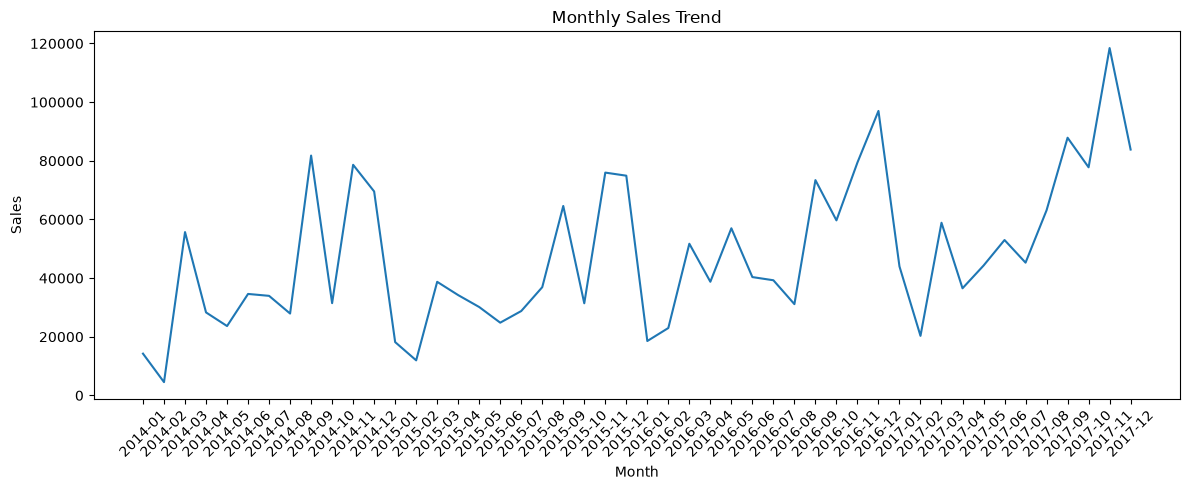

In [41]:
plt.figure(figsize=(12, 5))

plt.plot(forecast_df["Month"], forecast_df["Sales"])

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
print("Highest Monthly Sales:")
print(forecast_df.loc[forecast_df["Sales"].idxmax()])

print("\nLowest Monthly Sales:")
print(forecast_df.loc[forecast_df["Sales"].idxmin()])

Highest Monthly Sales:
Month       2017-11
Sales    118447.825
Name: 46, dtype: object

Lowest Monthly Sales:
Month     2014-02
Sales    4519.892
Name: 1, dtype: object


In [43]:
print(forecast_df)

      Month        Sales
0   2014-01   14236.8950
1   2014-02    4519.8920
2   2014-03   55691.0090
3   2014-04   28295.3450
4   2014-05   23648.2870
5   2014-06   34595.1276
6   2014-07   33946.3930
7   2014-08   27909.4685
8   2014-09   81777.3508
9   2014-10   31453.3930
10  2014-11   78628.7167
11  2014-12   69545.6205
12  2015-01   18174.0756
13  2015-02   11951.4110
14  2015-03   38726.2520
15  2015-04   34195.2085
16  2015-05   30131.6865
17  2015-06   24797.2920
18  2015-07   28765.3250
19  2015-08   36898.3322
20  2015-09   64595.9180
21  2015-10   31404.9235
22  2015-11   75972.5635
23  2015-12   74919.5212
24  2016-01   18542.4910
25  2016-02   22978.8150
26  2016-03   51715.8750
27  2016-04   38750.0390
28  2016-05   56987.7280
29  2016-06   40344.5340
30  2016-07   39261.9630
31  2016-08   31115.3743
32  2016-09   73410.0249
33  2016-10   59687.7450
34  2016-11   79411.9658
35  2016-12   96999.0430
36  2017-01   43971.3740
37  2017-02   20301.1334
38  2017-03   58872.3528


In [44]:
forecast_ml = forecast_df.copy()

forecast_ml["Month"] = pd.to_datetime(forecast_ml["Month"])

forecast_ml["Year"] = forecast_ml["Month"].dt.year
forecast_ml["Month_Number"] = forecast_ml["Month"].dt.month

print(forecast_ml.head())

       Month      Sales  Year  Month_Number
0 2014-01-01  14236.895  2014             1
1 2014-02-01   4519.892  2014             2
2 2014-03-01  55691.009  2014             3
3 2014-04-01  28295.345  2014             4
4 2014-05-01  23648.287  2014             5


In [45]:
print(forecast_ml.shape)
print(forecast_ml.info())

(48, 4)
<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Month         48 non-null     datetime64[us]
 1   Sales         48 non-null     float64       
 2   Year          48 non-null     int32         
 3   Month_Number  48 non-null     int32         
dtypes: datetime64[us](1), float64(1), int32(2)
memory usage: 1.3 KB
None


In [46]:
train_data = forecast_ml[forecast_ml["Year"] < 2017]
test_data = forecast_ml[forecast_ml["Year"] == 2017]

print("Training Data:")
print(train_data)

print("\nTesting Data:")
print(test_data)

print("\nTraining Rows:", len(train_data))
print("Testing Rows:", len(test_data))

Training Data:
        Month       Sales  Year  Month_Number
0  2014-01-01  14236.8950  2014             1
1  2014-02-01   4519.8920  2014             2
2  2014-03-01  55691.0090  2014             3
3  2014-04-01  28295.3450  2014             4
4  2014-05-01  23648.2870  2014             5
5  2014-06-01  34595.1276  2014             6
6  2014-07-01  33946.3930  2014             7
7  2014-08-01  27909.4685  2014             8
8  2014-09-01  81777.3508  2014             9
9  2014-10-01  31453.3930  2014            10
10 2014-11-01  78628.7167  2014            11
11 2014-12-01  69545.6205  2014            12
12 2015-01-01  18174.0756  2015             1
13 2015-02-01  11951.4110  2015             2
14 2015-03-01  38726.2520  2015             3
15 2015-04-01  34195.2085  2015             4
16 2015-05-01  30131.6865  2015             5
17 2015-06-01  24797.2920  2015             6
18 2015-07-01  28765.3250  2015             7
19 2015-08-01  36898.3322  2015             8
20 2015-09-01  6459

In [47]:
X_train = train_data[["Year", "Month_Number"]]
y_train = train_data["Sales"]

X_test = test_data[["Year", "Month_Number"]]
y_test = test_data["Sales"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (36, 2)
y_train shape: (36,)
X_test shape: (12, 2)
y_test shape: (12,)


In [48]:
from sklearn.linear_model import LinearRegression

In [49]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [50]:
linear_predictions = linear_model.predict(X_test)

print("Actual Sales:")
print(y_test.values)

print("\nPredicted Sales:")
print(linear_predictions)

Actual Sales:
[ 43971.374   20301.1334  58872.3528  36521.5361  44261.1102  52981.7257
  45264.416   63120.888   87866.652   77776.9232 118447.825   83829.3188]

Predicted Sales:
[26729.05779252 31661.45084439 36593.84389625 41526.23694812
 46458.62999998 51391.02305185 56323.41610371 61255.80915558
 66188.20220744 71120.59525931 76052.98831117 80985.38136303]


In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R2 Score:", linear_r2)

Linear Regression Results
-------------------------
MAE : 12180.97472158754
RMSE: 16833.856623498294
R2 Score: 0.5734000563937165


In [52]:
from sklearn.ensemble import RandomForestRegressor

In [53]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [54]:
rf_predictions = rf_model.predict(X_test)

print("Actual Sales:")
print(y_test.values)

print("\nRandom Forest Predicted Sales:")
print(rf_predictions)

Actual Sales:
[ 43971.374   20301.1334  58872.3528  36521.5361  44261.1102  52981.7257
  45264.416   63120.888   87866.652   77776.9232 118447.825   83829.3188]

Random Forest Predicted Sales:
[20510.967358  20563.094841  49209.325215  42519.1780725 50147.05058
 43101.578385  39834.857922  35770.4474735 70212.1736965 56101.2240355
 81520.63854   89739.5617615]


In [55]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("--------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Results
--------------------
MAE : 14174.727569124967
RMSE: 17723.9433820857
R2 Score: 0.5270946208890526


In [56]:
forecast_features = forecast_df.copy()

forecast_features["Month"] = pd.to_datetime(forecast_features["Month"])

forecast_features["Year"] = forecast_features["Month"].dt.year
forecast_features["Month_Number"] = forecast_features["Month"].dt.month

forecast_features["Lag_1"] = forecast_features["Sales"].shift(1)
forecast_features["Lag_2"] = forecast_features["Sales"].shift(2)
forecast_features["Lag_12"] = forecast_features["Sales"].shift(12)

forecast_features["Rolling_3"] = forecast_features["Sales"].shift(1).rolling(3).mean()

print(forecast_features.head(15))

        Month       Sales  Year  Month_Number       Lag_1       Lag_2  \
0  2014-01-01  14236.8950  2014             1         NaN         NaN   
1  2014-02-01   4519.8920  2014             2  14236.8950         NaN   
2  2014-03-01  55691.0090  2014             3   4519.8920  14236.8950   
3  2014-04-01  28295.3450  2014             4  55691.0090   4519.8920   
4  2014-05-01  23648.2870  2014             5  28295.3450  55691.0090   
5  2014-06-01  34595.1276  2014             6  23648.2870  28295.3450   
6  2014-07-01  33946.3930  2014             7  34595.1276  23648.2870   
7  2014-08-01  27909.4685  2014             8  33946.3930  34595.1276   
8  2014-09-01  81777.3508  2014             9  27909.4685  33946.3930   
9  2014-10-01  31453.3930  2014            10  81777.3508  27909.4685   
10 2014-11-01  78628.7167  2014            11  31453.3930  81777.3508   
11 2014-12-01  69545.6205  2014            12  78628.7167  31453.3930   
12 2015-01-01  18174.0756  2015             1  6954

In [57]:
forecast_features = forecast_features.dropna()

print("Rows after creating lag features:", len(forecast_features))
print(forecast_features.head())

Rows after creating lag features: 36
        Month       Sales  Year  Month_Number       Lag_1       Lag_2  \
12 2015-01-01  18174.0756  2015             1  69545.6205  78628.7167   
13 2015-02-01  11951.4110  2015             2  18174.0756  69545.6205   
14 2015-03-01  38726.2520  2015             3  11951.4110  18174.0756   
15 2015-04-01  34195.2085  2015             4  38726.2520  11951.4110   
16 2015-05-01  30131.6865  2015             5  34195.2085  38726.2520   

       Lag_12     Rolling_3  
12  14236.895  59875.910067  
13   4519.892  55449.470933  
14  55691.009  33223.702367  
15  28295.345  22950.579533  
16  23648.287  28290.957167  


In [58]:
train_features = forecast_features[forecast_features["Year"] < 2017]
test_features = forecast_features[forecast_features["Year"] == 2017]

print("Training Rows:", len(train_features))
print("Testing Rows:", len(test_features))

Training Rows: 24
Testing Rows: 12


In [59]:
feature_columns = [
    "Year",
    "Month_Number",
    "Lag_1",
    "Lag_2",
    "Lag_12",
    "Rolling_3"
]

X_train_lag = train_features[feature_columns]
y_train_lag = train_features["Sales"]

X_test_lag = test_features[feature_columns]
y_test_lag = test_features["Sales"]

print("X_train:", X_train_lag.shape)
print("y_train:", y_train_lag.shape)
print("X_test:", X_test_lag.shape)
print("y_test:", y_test_lag.shape)

X_train: (24, 6)
y_train: (24,)
X_test: (12, 6)
y_test: (12,)


In [60]:
improved_model = LinearRegression()

improved_model.fit(X_train_lag, y_train_lag)

print("Improved Linear Regression model trained successfully!")

Improved Linear Regression model trained successfully!


In [61]:
improved_predictions = improved_model.predict(X_test_lag)

print("Actual Sales:")
print(y_test_lag.values)

print("\nImproved Model Predictions:")
print(improved_predictions)

Actual Sales:
[ 43971.374   20301.1334  58872.3528  36521.5361  44261.1102  52981.7257
  45264.416   63120.888   87866.652   77776.9232 118447.825   83829.3188]

Improved Model Predictions:
[ 43865.92999991  44465.39960816  65014.29031146  58834.67280049
  69307.89331258  62269.57908684  62696.33205403  58257.23026989
  90894.67362693  84699.44966497  99455.73193574 118017.27095468]


In [62]:
improved_mae = mean_absolute_error(
    y_test_lag,
    improved_predictions
)

improved_rmse = np.sqrt(
    mean_squared_error(
        y_test_lag,
        improved_predictions
    )
)

improved_r2 = r2_score(
    y_test_lag,
    improved_predictions
)

print("Improved Linear Regression Results")
print("----------------------------------")
print("MAE :", improved_mae)
print("RMSE:", improved_rmse)
print("R2 Score:", improved_r2)

Improved Linear Regression Results
----------------------------------
MAE : 14373.799001216257
RMSE: 17671.211836872604
R2 Score: 0.5299043720860391


In [63]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Improved Linear Regression"
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        improved_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        improved_rmse
    ],
    "R2 Score": [
        linear_r2,
        rf_r2,
        improved_r2
    ]
})

print(comparison)

                        Model           MAE          RMSE  R2 Score
0           Linear Regression  12180.974722  16833.856623  0.573400
1               Random Forest  14174.727569  17723.943382  0.527095
2  Improved Linear Regression  14373.799001  17671.211837  0.529904


In [64]:
future_dates = pd.date_range(
    start="2018-01-01",
    periods=12,
    freq="MS"
)

future_data = pd.DataFrame({
    "Month": future_dates
})

future_data["Year"] = future_data["Month"].dt.year
future_data["Month_Number"] = future_data["Month"].dt.month

print(future_data)

        Month  Year  Month_Number
0  2018-01-01  2018             1
1  2018-02-01  2018             2
2  2018-03-01  2018             3
3  2018-04-01  2018             4
4  2018-05-01  2018             5
5  2018-06-01  2018             6
6  2018-07-01  2018             7
7  2018-08-01  2018             8
8  2018-09-01  2018             9
9  2018-10-01  2018            10
10 2018-11-01  2018            11
11 2018-12-01  2018            12


In [65]:
future_X = future_data[["Year", "Month_Number"]]

future_predictions = linear_model.predict(future_X)

future_data["Predicted_Sales"] = future_predictions

print(future_data)

        Month  Year  Month_Number  Predicted_Sales
0  2018-01-01  2018             1     31935.645288
1  2018-02-01  2018             2     36868.038340
2  2018-03-01  2018             3     41800.431392
3  2018-04-01  2018             4     46732.824444
4  2018-05-01  2018             5     51665.217496
5  2018-06-01  2018             6     56597.610548
6  2018-07-01  2018             7     61530.003600
7  2018-08-01  2018             8     66462.396651
8  2018-09-01  2018             9     71394.789703
9  2018-10-01  2018            10     76327.182755
10 2018-11-01  2018            11     81259.575807
11 2018-12-01  2018            12     86191.968859


In [66]:
total_forecast = future_data["Predicted_Sales"].sum()

print("Total Predicted Sales for 2018:", total_forecast)

Total Predicted Sales for 2018: 708765.6848833449


In [67]:
highest_forecast = future_data.loc[
    future_data["Predicted_Sales"].idxmax()
]

print("Highest Predicted Sales Month:")
print(highest_forecast)

Highest Predicted Sales Month:
Month              2018-12-01 00:00:00
Year                              2018
Month_Number                        12
Predicted_Sales           86191.968859
Name: 11, dtype: object


In [68]:
lowest_forecast = future_data.loc[
    future_data["Predicted_Sales"].idxmin()
]

print("\nLowest Predicted Sales Month:")
print(lowest_forecast)


Lowest Predicted Sales Month:
Month              2018-01-01 00:00:00
Year                              2018
Month_Number                         1
Predicted_Sales           31935.645288
Name: 0, dtype: object


In [69]:
discount_analysis = df.groupby("Discount").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
}).reset_index()

print(discount_analysis)

    Discount         Sales       Profit  Quantity
0       0.00  1.087908e+06  320987.6032     18267
1       0.10  5.436935e+04    9029.1770       373
2       0.15  2.755852e+04    1418.9915       198
3       0.20  7.645944e+05   90337.3060     13660
4       0.30  1.032267e+05  -10369.2774       849
5       0.32  1.449346e+04   -2391.1377       105
6       0.40  1.164178e+05  -23057.0504       786
7       0.45  5.484974e+03   -2493.1111        45
8       0.50  5.891854e+04  -20506.4281       241
9       0.60  6.644700e+03   -5944.6552       501
10      0.70  4.062028e+04  -40075.3569      1660
11      0.80  1.696376e+04  -30539.0392      1188


In [70]:
discount_analysis["Recommendation"] = ""

for i in range(len(discount_analysis)):
    if discount_analysis.loc[i, "Profit"] < 0:
        discount_analysis.loc[i, "Recommendation"] = "Review discount - loss making"
    else:
        discount_analysis.loc[i, "Recommendation"] = "Discount level profitable"

print(discount_analysis)

    Discount         Sales       Profit  Quantity  \
0       0.00  1.087908e+06  320987.6032     18267   
1       0.10  5.436935e+04    9029.1770       373   
2       0.15  2.755852e+04    1418.9915       198   
3       0.20  7.645944e+05   90337.3060     13660   
4       0.30  1.032267e+05  -10369.2774       849   
5       0.32  1.449346e+04   -2391.1377       105   
6       0.40  1.164178e+05  -23057.0504       786   
7       0.45  5.484974e+03   -2493.1111        45   
8       0.50  5.891854e+04  -20506.4281       241   
9       0.60  6.644700e+03   -5944.6552       501   
10      0.70  4.062028e+04  -40075.3569      1660   
11      0.80  1.696376e+04  -30539.0392      1188   

                   Recommendation  
0       Discount level profitable  
1       Discount level profitable  
2       Discount level profitable  
3       Discount level profitable  
4   Review discount - loss making  
5   Review discount - loss making  
6   Review discount - loss making  
7   Review discount - 

In [71]:
product_profit = df.groupby("Product Name")["Profit"].sum().reset_index()

loss_products = product_profit[
    product_profit["Profit"] < 0
].sort_values("Profit")

print(loss_products.head(10))

                                           Product Name     Profit
475           Cubify CubeX 3D Printer Double Head Print -8879.9704
985           Lexmark MX611dhe Monochrome Laser Printer -4589.9730
476           Cubify CubeX 3D Printer Triple Head Print -3839.9904
425   Chromcraft Bull-Nose Wood Oval Conference Tabl... -2876.1156
376   Bush Advantage Collection Racetrack Conference... -1934.3976
683           GBC DocuBind P400 Electric Binding System -1878.1662
444   Cisco TelePresence System EX90 Videoconferenci... -1811.0784
1043  Martin Yale Chadless Opener Electric Letter Op... -1299.1836
285                        Balt Solid Wood Round Tables -1201.0581
364   BoxOffice By Design Rectangular and Half-Moon ... -1148.4375


In [72]:
category_profit = df.groupby("Category")["Profit"].sum().reset_index()

best_category = category_profit.loc[
    category_profit["Profit"].idxmax()
]

print("Most Profitable Category:")
print(best_category)

Most Profitable Category:
Category     Technology
Profit      145454.9481
Name: 2, dtype: object


In [73]:
recommendations = []

# Discount recommendation
loss_discounts = discount_analysis[
    discount_analysis["Profit"] < 0
]

if len(loss_discounts) > 0:
    recommendations.append(
        "High discount levels are causing negative profit. Review discounts of 30% and above."
    )

# Product recommendation
if len(loss_products) > 0:
    recommendations.append(
        "Several products are generating negative profit. Review pricing, discounts, and product costs."
    )

# Category recommendation
recommendations.append(
    "Technology is the most profitable category and should receive strategic attention."
)

print("SMARTRETAIL AI - BUSINESS RECOMMENDATIONS")
print("-------------------------------------------")

for i in range(len(recommendations)):
    print(str(i + 1) + ".", recommendations[i])

SMARTRETAIL AI - BUSINESS RECOMMENDATIONS
-------------------------------------------
1. High discount levels are causing negative profit. Review discounts of 30% and above.
2. Several products are generating negative profit. Review pricing, discounts, and product costs.
3. Technology is the most profitable category and should receive strategic attention.


In [74]:
profitable_discounts = discount_analysis[
    discount_analysis["Profit"] >= 0
]

loss_making_discounts = discount_analysis[
    discount_analysis["Profit"] < 0
]

print("Profitable Discount Levels:")
print(profitable_discounts["Discount"].tolist())

print("\nLoss-Making Discount Levels:")
print(loss_making_discounts["Discount"].tolist())

Profitable Discount Levels:
[0.0, 0.1, 0.15, 0.2]

Loss-Making Discount Levels:
[0.3, 0.32, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8]
